# Importing dependencies

In [1]:
import os
import pandas as pd
from torchinfo import summary
import shutil
from sklearn.model_selection import train_test_split
import glob
import torch
import random
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, Subset
import numpy as np
import seaborn as sns
import torch.optim as optim
from torch.optim.lr_scheduler import _LRScheduler
from torch.optim.lr_scheduler import ReduceLROnPlateau
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from tqdm import tqdm
from sklearn.metrics import classification_report
from sklearn.metrics import roc_auc_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import cv2
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import ConcatDataset, Dataset

In [2]:
SEED = 1234

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

**Defining the batch size and image size**

In [3]:
BATCH_SIZE = 16
IMG_SIZE = 224

# Setting the directories path

In [4]:
csv_path = '/kaggle/input/datasets/britikak/bus-uclm/BUS-UCLM Breast ultrasound lesion segmentation dataset/BUS-UCLM/INFO.csv'
img_dir = '/kaggle/input/datasets/britikak/bus-uclm/BUS-UCLM Breast ultrasound lesion segmentation dataset/BUS-UCLM/images'
df = pd.read_csv(csv_path, sep=';')
df.head(2)

,Image,Resolution,Label,Doppler,Marks,Combined
0,ALWI_000.png,856x606,Benign,No,Yes,No
1,ALWI_001.png,856x606,Normal,No,No,No


**Exploring the dataframe columns**

In [5]:
df.columns

Index(['Image', 'Resolution', 'Label', 'Doppler', 'Marks', 'Combined'], dtype='object')

**Redefining the dataframe**

In [6]:
df = df[['Image', 'Label']]
df = df.dropna().reset_index(drop=True)
df = df.rename(columns={'Label': 'Classification'})
df.head()

,Image,Classification
0,ALWI_000.png,Benign
1,ALWI_001.png,Normal
2,ALWI_002.png,Benign
3,ALWI_003.png,Benign
4,ALWI_004.png,Benign


**Visualizing the class distribution**

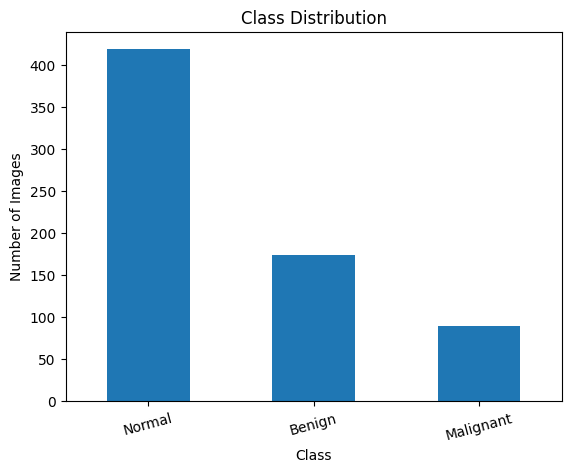

In [7]:
df['Classification'].value_counts().plot(kind='bar')
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.show()

In [8]:
class_counts = df['Classification'].value_counts()    # pandas.core.series.Series
print(class_counts)

Classification
Normal       419
Benign       174
Malignant     90
Name: count, dtype: int64


**Labelling the classes**

In [9]:
label_map = {
    'Normal': 0,
    'Malignant': 1,
    'Benign': 2
}

class_names = class_names = ["Normal", "Malignant", "Benign"]
print(class_names)
print("\nClass mapping:")
print(label_map,'\n')

df['label'] = df['Classification'].map(label_map)
df.head()

['Normal', 'Malignant', 'Benign']

Class mapping:
{'Normal': 0, 'Malignant': 1, 'Benign': 2} 



,Image,Classification,label
0,ALWI_000.png,Benign,2
1,ALWI_001.png,Normal,0
2,ALWI_002.png,Benign,2
3,ALWI_003.png,Benign,2
4,ALWI_004.png,Benign,2


# Train Test Split on the input dataframe

In [10]:
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df['label'],
    shuffle=True,
    random_state=42
)

val_df, test_df = train_test_split(
    test_df,
    test_size=0.5,
    shuffle=True,
    random_state=42
)

print("Train size:", len(train_df))
print("Validation size:", len(val_df))
print("Test size:", len(test_df))

Train size: 546
Validation size: 68
Test size: 69


**Exploring the class distribution in train vs test data: Verifying Class Imbalance**

In [11]:
print("Train distribution:")
print(train_df['label'].value_counts())

print("Validation distribution:")
print(val_df['label'].value_counts())

print("\n\nTest distribution:")
print(test_df['label'].value_counts())

Train distribution:
label
0    335
2    139
1     72
Name: count, dtype: int64
Validation distribution:
label
0    41
2    17
1    10
Name: count, dtype: int64


Test distribution:
label
0    43
2    18
1     8
Name: count, dtype: int64


# Calculating the initial class weights

In [12]:
class_counts = train_df['Classification'].value_counts()
print("Class Counts:")
for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

counts_array = np.array([
    class_counts['Normal'],
    class_counts['Malignant'],
    class_counts['Benign']
])

class_weights = 1.0 / counts_array
class_weights = class_weights / class_weights.sum()

weights_tensor = torch.tensor(class_weights, dtype=torch.float32)

print(weights_tensor)

Class Counts:
Normal: 335
Benign: 139
Malignant: 72
tensor([0.1240, 0.5771, 0.2989])


# Class definition for Dataset Formation

In [13]:
class BUSUCLMDataset(Dataset):
    def __init__(self, dataframe, image_dir, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_name = self.df.iloc[idx]['Image']
        label = self.df.iloc[idx]['label']

        image_path = os.path.join(self.image_dir, img_name)
        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label)


**Calcuating the mean and std on the dataset**

In [14]:
tmp_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

temp_train_dataset = BUSUCLMDataset(
    dataframe=train_df,
    image_dir=img_dir,
    transform=tmp_transform
)

temp_loader = DataLoader(
    temp_train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

mean = 0.
std = 0.
total_images = 0

for images, _ in temp_loader:
    batch_samples = images.size(0)
    images = images.view(batch_samples, images.size(1), -1)

    mean += images.mean(2).sum(0)
    std += images.std(2).sum(0)
    total_images += batch_samples

mean /= total_images
std /= total_images

print("Calculated Mean:", mean)
print("Calculated Std:", std)

Calculated Mean: tensor([0.2420, 0.2532, 0.2768])
Calculated Std: tensor([0.1407, 0.1457, 0.1579])


# **Data augmentation**

In [15]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(8),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.05,0.05),
        scale=(0.9,1.1)
    ),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

val_test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE,IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Loading the Train, Validation and Test Datasets

In [16]:
from torch.utils.data import ConcatDataset

train_dataset = BUSUCLMDataset(train_df, img_dir, transform=train_transform)
val_dataset   = BUSUCLMDataset(val_df, img_dir, transform=val_test_transform)
test_dataset  = BUSUCLMDataset(test_df, img_dir, transform=val_test_transform)
    
train_loader = DataLoader(train_dataset,
                          batch_size=BATCH_SIZE,
                          shuffle=True,
                          drop_last=True,
                          num_workers=4, 
                          pin_memory=True,
                          persistent_workers=True)

val_loader   = DataLoader(val_dataset, 
                          batch_size=BATCH_SIZE, 
                          shuffle=False)

test_loader   = DataLoader(test_dataset, 
                           batch_size=BATCH_SIZE, 
                           shuffle=False)

# MedicalImageClassifier class definition for DenseNet121

In [17]:
import torch
import torch.nn as nn
import torchvision.models as models

In [ ]:
class ChannelAttention(nn.Module):
 
    def __init__(self, in_channels: int, reduction: int = 16):
        super().__init__()
        bottleneck = max(in_channels // reduction, 1)
        self.mlp = nn.Sequential(
            nn.Linear(in_channels, bottleneck, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(bottleneck, in_channels, bias=False),
        )
 
    def forward(self, x: torch.Tensor):
        # x : (B, C, H, W)
        avg_out = self.mlp(x.mean(dim=[2, 3]))        # (B, C)
        max_out = self.mlp(x.amax(dim=[2, 3]))        # (B, C)
        gate    = torch.sigmoid(avg_out + max_out)    # (B, C)
        return x * gate.unsqueeze(-1).unsqueeze(-1)   # (B, C, H, W)

In [ ]:
class SpatialAttention(nn.Module):
 
    def __init__(self, kernel_size: int = 7):
        super().__init__()
        assert kernel_size in (3, 7), "kernel_size must be 3 or 7"
        self.conv = nn.Conv2d(2, 1, kernel_size=kernel_size,
                              padding=(kernel_size - 1) // 2, bias=False)
 
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Pool along channel dim → (B, 1, H, W) each
        avg_pool = x.mean(dim=1, keepdim=True)
        max_pool = x.amax(dim=1, keepdim=True)
        gate     = torch.sigmoid(self.conv(torch.cat([avg_pool, max_pool], dim=1)))
        return x * gate   # (B, C, H, W)

In [ ]:
class CBAM(nn.Module):
 
    def __init__(self, in_channels: int, reduction_ratio: int = 16, spatial_kernel: int = 7):
        super().__init__()
        self.channel_att = ChannelAttention(in_channels, reduction_ratio)
        self.spatial_att = SpatialAttention(spatial_kernel)
 
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.channel_att(x)   # what  — recalibrate channels
        x = self.spatial_att(x)   # where — recalibrate spatial locations
        return x

In [ ]:
class SEBlock(nn.Module):
 
    def __init__(self, in_channels: int, reduction: int = 16):
        super().__init__()
 
        bottleneck = max(in_channels // reduction, 1)
 
        self.squeeze  = nn.AdaptiveAvgPool2d(1)   # (B, C, H, W) → (B, C, 1, 1)
 
        self.excite = nn.Sequential(
            nn.Flatten(),                                       # (B, C, 1, 1) → (B, C)
            nn.Linear(in_channels, bottleneck, bias=False),    # compress
            nn.ReLU(inplace=True),
            nn.Linear(bottleneck, in_channels, bias=False),    # restore
            nn.Sigmoid(),                                       # gate ∈ (0, 1)
        )
 
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x : (B, C, H, W)
        scale = self.squeeze(x)          # (B, C, 1, 1)
        scale = self.excite(scale)       # (B, C)
        scale = scale.unsqueeze(-1).unsqueeze(-1)   # (B, C, 1, 1)  broadcast-ready
        return x * scale                 # (B, C, H, W)  channel-recalibrated

In [ ]:
class CBAM_SE(nn.Module):
    
    def __init__(self, in_channels: int, reduction: int = 16, spatial_kernel: int = 7):
        super().__init__()
        self.cbam = CBAM(in_channels, reduction, spatial_kernel)
        self.se   = SEBlock(in_channels, reduction)
        self.alpha = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_channels, in_channels, 1),
            nn.Sigmoid()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        alpha = self.alpha(x)   # shape: (B, C, 1, 1)

        se_out = self.se(x)
        cbam_out = self.cbam(x)
        
        return alpha * se_out + (1 - alpha) * cbam_out

In [ ]:
class DenseNetBackbone(nn.Module):
    
    def __init__(self, pretrained=True):
        super().__init__()

        backbone = models.densenet121(
            weights=models.DenseNet121_Weights.DEFAULT if pretrained else None
        )

        features = backbone.features

        self.conv = nn.Sequential(
            features.conv0,
            features.norm0,
            features.relu0,
            features.pool0
        )

        self.db1 = features.denseblock1
        self.tr1 = features.transition1

        self.db2 = features.denseblock2
        self.tr2 = features.transition2

        self.db3 = features.denseblock3
        self.tr3 = features.transition3

        self.db4 = features.denseblock4

    def forward(self, x):
        x = self.conv(x)

        c1 = self.tr1(self.db1(x))   # 128
        c2 = self.tr2(self.db2(c1))  # 256
        c3 = self.tr3(self.db3(c2))  # 512
        c4 = self.db4(c3)            # 1024

        return c1, c2, c3, c4

In [24]:
# feature pyramid network

class FPN(nn.Module):
    def __init__(self):
        super().__init__()

        self.lateral = nn.ModuleList([
            nn.Conv2d(128, 256, 1),
            nn.Conv2d(256, 256, 1),
            nn.Conv2d(512, 256, 1),
            nn.Conv2d(1024, 256, 1),
        ])

        self.smooth = nn.ModuleList([
            nn.Conv2d(256, 256, 3, padding=1) for _ in range(4)
        ])

    def forward(self, c1, c2, c3, c4):
        p4 = self.lateral[3](c4)
    
        p3 = self.lateral[2](c3) + F.interpolate(
            p4, size=c3.shape[-2:], mode='nearest'
        )
    
        p2 = self.lateral[1](c2) + F.interpolate(
            p3, size=c2.shape[-2:], mode='nearest'
        )
    
        p1 = self.lateral[0](c1) + F.interpolate(
            p2, size=c1.shape[-2:], mode='nearest'
        )

        
        return p1, p2, p3, p4

In [25]:
class MultiScaleAttention(nn.Module):
    def __init__(self, channels=256):
        super().__init__()

        self.cbamse = CBAM_SE(in_channels=channels)

    def forward(self, p1, p2, p3, p4):
        p1 = self.cbamse(p1)
        p2 = self.cbamse(p2)

        p3 = self.cbamse(p3)
        p4 = self.cbamse(p4)

        return p1, p2, p3, p4
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models

In [26]:
class MedicalImageClassifier(nn.Module):
    def __init__(self, num_classes=2, pretrained=True):
        super().__init__()

        self.backbone = DenseNetBackbone(pretrained)
        self.fpn = FPN()
        self.attn = MultiScaleAttention(256)

        self.pool = nn.AdaptiveAvgPool2d(1)

        # updated classifier (input now 256*4 = 1024)
        self.classifier = nn.Sequential(
            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        c1, c2, c3, c4 = self.backbone(x)

        p1, p2, p3, p4 = self.fpn(c1, c2, c3, c4)

        p1, p2, p3, p4 = self.attn(p1, p2, p3, p4)

        # global pooling
        p1 = self.pool(p1).flatten(1)
        p2 = self.pool(p2).flatten(1)
        p3 = self.pool(p3).flatten(1)
        p4 = self.pool(p4).flatten(1)

        features = torch.cat([p1, p2, p3, p4], dim=1)

        return self.classifier(features)

In [27]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model = MedicalImageClassifier(num_classes=len(class_counts.keys())).to(device)

print(summary(model, input_size=(BATCH_SIZE, 3, IMG_SIZE, IMG_SIZE)))

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 167MB/s] 


Layer (type:depth-idx)                        Output Shape              Param #
MedicalImageClassifier                        [16, 3]                   --
├─DenseNetBackbone: 1-1                       [16, 128, 28, 28]         --
│    └─Sequential: 2-1                        [16, 64, 56, 56]          --
│    │    └─Conv2d: 3-1                       [16, 64, 112, 112]        9,408
│    │    └─BatchNorm2d: 3-2                  [16, 64, 112, 112]        128
│    │    └─ReLU: 3-3                         [16, 64, 112, 112]        --
│    │    └─MaxPool2d: 3-4                    [16, 64, 56, 56]          --
│    └─_DenseBlock: 2-2                       [16, 256, 56, 56]         --
│    │    └─_DenseLayer: 3-5                  [16, 32, 56, 56]          45,440
│    │    └─_DenseLayer: 3-6                  [16, 32, 56, 56]          49,600
│    │    └─_DenseLayer: 3-7                  [16, 32, 56, 56]          53,760
│    │    └─_DenseLayer: 3-8                  [16, 32, 56, 56]          57,920


**Defining Loss function, optimizer, and scheduler**

In [28]:
class_weights = weights_tensor.to(device)  # Adjust based on your dataset
criterion = nn.CrossEntropyLoss(weight=class_weights.to(device), label_smoothing=0.1)
optimizer = optim.Adam(model.parameters(), lr= 1e-4, weight_decay=1e-4)
scheduler = ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.1,
    patience=10
)

In [29]:
def compute_metrics(labels, preds):
    acc = accuracy_score(labels, preds)
    prec = precision_score(labels, preds, average='weighted', zero_division=0)
    rec = recall_score(labels, preds, average='weighted', zero_division=0)
    f1 = f1_score(labels, preds, average='weighted', zero_division=0)

    cm = confusion_matrix(labels, preds)
    sensitivity_per_class, specificity_per_class = [], []

    for i in range(cm.shape[0]):
        TP = cm[i, i]
        FN = np.sum(cm[i, :]) - TP
        FP = np.sum(cm[:, i]) - TP
        TN = np.sum(cm) - (TP + FP + FN)

        sensitivity = TP / (TP + FN + 1e-8)
        specificity = TN / (TN + FP + 1e-8)

        sensitivity_per_class.append(sensitivity)
        specificity_per_class.append(specificity)

    return (
        acc, prec, rec, f1,
        np.mean(sensitivity_per_class),
        np.mean(specificity_per_class)
    )


In [30]:
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    all_preds, all_labels = [], []
    running_loss = 0.0

    for images, labels in tqdm(loader, desc="Training", leave=False):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        preds = torch.argmax(outputs, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    acc, prec, rec, f1,sensitivity_macro, specificity_macro = compute_metrics(all_labels, all_preds)
    return epoch_loss, acc, prec, rec, f1,sensitivity_macro, specificity_macro

In [31]:
def validate_one_epoch(model, loader, criterion, device):
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    running_loss = 0.0

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Validation", leave=False):
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            probs = torch.softmax(outputs, dim=1)
            preds = torch.argmax(probs, dim=1)

            all_probs.extend(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    acc, prec, rec, f1, sensitivity_macro, specificity_macro = compute_metrics(all_labels, all_preds)

    auc = roc_auc_score(all_labels, all_probs, multi_class='ovr', average='macro')

    return epoch_loss, acc, prec, rec, f1, sensitivity_macro, specificity_macro, auc

# Training and Validating the model

In [32]:
num_epochs = 100
unfreeze_epoch = 16
global_best_val_loss = float('inf')
global_best_path = "best_model_overall.pth"

# Early stopping settings
early_stopping_patience = 20
early_stopping_counter = 0
min_delta = 1e-4   # minimum change to qualify as improvement

# Logs
train_losses, val_losses = [], []
train_accs, val_accs = [], []

best_val_acc = 0.0
best_val_auc = 0.0

for epoch in range(1, num_epochs + 1):

    train_loss, train_acc, train_prec, train_rec, train_f1, train_sensitivity_macro, train_specificity_macro = train_one_epoch(
        model, train_loader, optimizer, criterion, device
    )

    val_loss, val_acc, val_prec, val_rec, val_f1, val_sensitivity_macro, val_specificity_macro, val_auc = validate_one_epoch(
        model, val_loader, criterion, device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    current_lrs = [group['lr'] for group in optimizer.param_groups]
    print(f"\nCurrent LRs: {current_lrs}")

    print(f"Epoch {epoch:02d} | "
          f"Train - Loss: {train_loss:.4f} | "
          f"Acc: {train_acc:.4f} | "
          f"Prec: {train_prec:.4f} | "
          f"Recall: {train_rec:.4f} | "
          f"F1: {train_f1:.4f} | "
          f"Specificity: {train_specificity_macro:.4f} | "
          f"Sensitivity: {train_sensitivity_macro:.4f}")

    print(f"Epoch {epoch:02d} | "
          f"Val - Loss: {val_loss:.4f} | "
          f"Acc: {val_acc:.4f} | "
          f"Prec: {val_prec:.4f} | "
          f"Recall: {val_rec:.4f} | "
          f"F1: {val_f1:.4f} | "
          f"Specificity: {val_specificity_macro:.4f} | "
          f"Sensitivity: {val_sensitivity_macro:.4f} | "
          f"AUC: {val_auc:.4f}")

    scheduler.step(val_loss)

    # Early Stopping + Best Model Saving
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save(model.state_dict(), global_best_path)
        print(f"\n✅ Saved best model (Val AUC: {val_auc:.4f})")
        early_stopping_counter = 0
    # else:
    #     early_stopping_counter += 1
    #     print(f"Early Stopping Counter: {early_stopping_counter}/{early_stopping_patience}")

    # if early_stopping_counter >= early_stopping_patience:
    #     print("\n⛔ Early stopping triggered.")
    #     break

print("\nTraining Complete")


Current LRs: [0.0001]
Epoch 01 | Train - Loss: 1.1014 | Acc: 0.5184 | Prec: 0.5713 | Recall: 0.5184 | F1: 0.5385 | Specificity: 0.7374 | Sensitivity: 0.4560
Epoch 01 | Val - Loss: 1.1384 | Acc: 0.2500 | Prec: 0.0634 | Recall: 0.2500 | F1: 0.1012 | Specificity: 0.6675 | Sensitivity: 0.3333 | AUC: 0.7523

✅ Saved best model (Val AUC: 0.7523)



Current LRs: [0.0001]
Epoch 02 | Train - Loss: 0.9311 | Acc: 0.6324 | Prec: 0.7176 | Recall: 0.6324 | F1: 0.6547 | Specificity: 0.8232 | Sensitivity: 0.6423
Epoch 02 | Val - Loss: 1.0351 | Acc: 0.2794 | Prec: 0.7276 | Recall: 0.2794 | F1: 0.1930 | Specificity: 0.7050 | Sensitivity: 0.4571 | AUC: 0.8219

✅ Saved best model (Val AUC: 0.8219)



Current LRs: [0.0001]
Epoch 03 | Train - Loss: 0.7965 | Acc: 0.7353 | Prec: 0.7888 | Recall: 0.7353 | F1: 0.7501 | Specificity: 0.8716 | Sensitivity: 0.7372
Epoch 03 | Val - Loss: 0.8404 | Acc: 0.7794 | Prec: 0.8084 | Recall: 0.7794 | F1: 0.7813 | Specificity: 0.8919 | Sensitivity: 0.6924 | AUC: 0.9155

✅ Saved best model (Val AUC: 0.9155)



Current LRs: [0.0001]
Epoch 04 | Train - Loss: 0.6624 | Acc: 0.8511 | Prec: 0.8812 | Recall: 0.8511 | F1: 0.8588 | Specificity: 0.9307 | Sensitivity: 0.8628
Epoch 04 | Val - Loss: 0.7953 | Acc: 0.7206 | Prec: 0.7628 | Recall: 0.7206 | F1: 0.7341 | Specificity: 0.8647 | Sensitivity: 0.6873 | AUC: 0.9004



Current LRs: [0.0001]
Epoch 05 | Train - Loss: 0.6009 | Acc: 0.8750 | Prec: 0.8932 | Recall: 0.8750 | F1: 0.8788 | Specificity: 0.9411 | Sensitivity: 0.8937
Epoch 05 | Val - Loss: 0.8050 | Acc: 0.8088 | Prec: 0.8186 | Recall: 0.8088 | F1: 0.8117 | Specificity: 0.9008 | Sensitivity: 0.7591 | AUC: 0.9176

✅ Saved best model (Val AUC: 0.9176)



Current LRs: [0.0001]
Epoch 06 | Train - Loss: 0.5881 | Acc: 0.8989 | Prec: 0.9088 | Recall: 0.8989 | F1: 0.9013 | Specificity: 0.9500 | Sensitivity: 0.9047
Epoch 06 | Val - Loss: 0.7091 | Acc: 0.7794 | Prec: 0.8137 | Recall: 0.7794 | F1: 0.7891 | Specificity: 0.8908 | Sensitivity: 0.7703 | AUC: 0.9307

✅ Saved best model (Val AUC: 0.9307)


... (90 outputs left out)


Current LRs: [1.0000000000000004e-08]
Epoch 97 | Train - Loss: 0.4398 | Acc: 0.9926 | Prec: 0.9928 | Recall: 0.9926 | F1: 0.9927 | Specificity: 0.9969 | Sensitivity: 0.9960
Epoch 97 | Val - Loss: 0.6790 | Acc: 0.8971 | Prec: 0.8969 | Recall: 0.8971 | F1: 0.8953 | Specificity: 0.9376 | Sensitivity: 0.8445 | AUC: 0.9474



Current LRs: [1.0000000000000004e-08]
Epoch 98 | Train - Loss: 0.4286 | Acc: 0.9982 | Prec: 0.9982 | Recall: 0.9982 | F1: 0.9982 | Specificity: 0.9993 | Sensitivity: 0.9990
Epoch 98 | Val - Loss: 0.6964 | Acc: 0.8971 | Prec: 0.8969 | Recall: 0.8971 | F1: 0.8953 | Specificity: 0.9376 | Sensitivity: 0.8445 | AUC: 0.9475



Current LRs: [1.0000000000000004e-08]
Epoch 99 | Train - Loss: 0.4383 | Acc: 0.9871 | Prec: 0.9878 | Recall: 0.9871 | F1: 0.9872 | Specificity: 0.9943 | Sensitivity: 0.9930
Epoch 99 | Val - Loss: 0.6693 | Acc: 0.8824 | Prec: 0.8815 | Recall: 0.8824 | F1: 0.8815 | Specificity: 0.9319 | Sensitivity: 0.8364 | AUC: 0.9497



Current LRs: [1.0000000000000004e-08]
Epoch 100 | Train - Loss: 0.4452 | Acc: 0.9926 | Prec: 0.9928 | Recall: 0.9926 | F1: 0.9927 | Specificity: 0.9968 | Sensitivity: 0.9960
Epoch 100 | Val - Loss: 0.6636 | Acc: 0.8824 | Prec: 0.8815 | Recall: 0.8824 | F1: 0.8815 | Specificity: 0.9319 | Sensitivity: 0.8364 | AUC: 0.9483

Training Complete


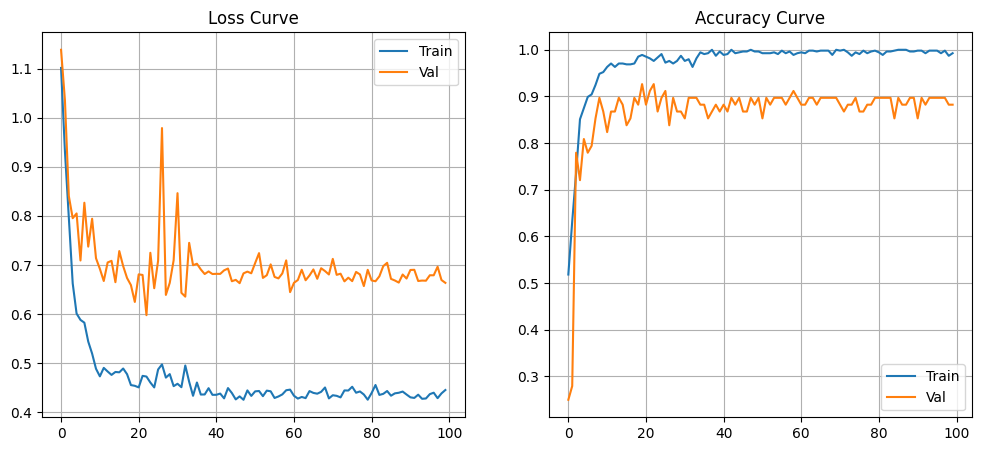

In [33]:
def plot_curves(train_losses, val_losses, train_accs, val_accs):
    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    plt.plot(train_losses, label="Train")
    plt.plot(val_losses, label="Val")
    plt.title("Loss Curve")
    plt.legend()
    plt.grid()

    plt.subplot(1,2,2)
    plt.plot(train_accs, label="Train")
    plt.plot(val_accs, label="Val")
    plt.title("Accuracy Curve")
    plt.legend()
    plt.grid()

    plt.show()


plot_curves(train_losses, val_losses, train_accs, val_accs)



# Loading the best model so far

In [34]:
model.load_state_dict(
    torch.load(global_best_path, map_location=device),
    strict=True
)

<All keys matched successfully>

# Testing the model


Classification Report:
              precision    recall  f1-score   support

      Normal       0.95      0.95      0.95        43
   Malignant       0.75      0.75      0.75         8
      Benign       0.89      0.89      0.89        18

    accuracy                           0.91        69
   macro avg       0.86      0.86      0.86        69
weighted avg       0.91      0.91      0.91        69



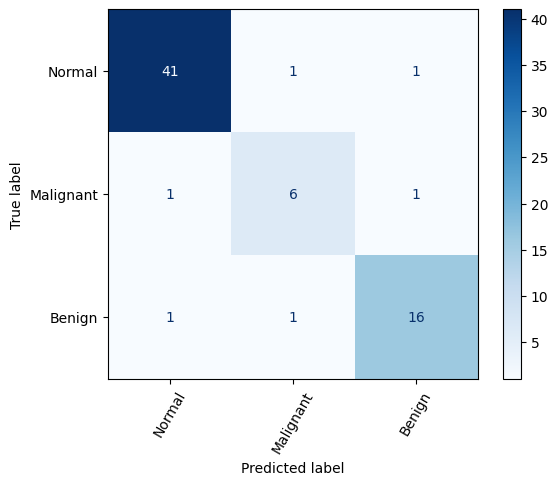

Test - Loss: 0.6810 | Acc: 0.9130 | Precision: 0.9130 | Recall: 0.9130 | F1: 0.9130 | Specificity: 0.9504 | Sensitivity: 0.8641


In [35]:
def test_model(model, loader, criterion, device, class_names):
    model.eval()
    all_preds, all_labels, all_probs, all_images = [], [], [], []
    running_loss = 0.0

    with torch.no_grad():
        for images, labels in tqdm(loader, desc="Testing", leave=False):
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            probs = torch.softmax(outputs, dim=1)

            all_preds.extend(probs.argmax(1).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.append(probs.cpu().numpy())
            all_images.extend(images.cpu())

    all_probs = np.concatenate(all_probs, axis=0)
    avg_loss = running_loss / len(loader.dataset)

    acc, prec, rec, f1, sens, spec = compute_metrics(all_labels, all_preds)

    print("\nClassification Report:")
    print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))

    cm = confusion_matrix(all_labels, all_preds)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
    plt.xticks(rotation=60)
    plt.show()

    return avg_loss, acc, prec, rec, f1, sens, spec, all_labels, all_images, all_preds, torch.tensor(np.vstack(all_probs))

test_loss, test_acc, test_prec, test_rec, test_f1, test_sensitivity, test_specificity, all_labels, all_images, all_preds, all_probs = test_model(
    model, test_loader, criterion, device, class_names
)

print(f"Test - Loss: {test_loss:.4f} | "
              f"Acc: {test_acc:.4f} | "
              f"Precision: {test_prec:.4f} | " 
              f"Recall: {test_rec:.4f} | "
              f"F1: {test_f1:.4f} | " 
              f"Specificity: {test_specificity:.4f} | " 
              f"Sensitivity: {test_sensitivity:.4f}")

In [36]:
def normalize_image(img_tensor):
    img = img_tensor.clone()
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)
    return img

def plot_most_incorrect(incorrect, classes, n_images, normalize=True):
    rows = int(np.sqrt(n_images))
    cols = int(np.sqrt(n_images))

    fig = plt.figure(figsize=(25, 20))
    for i in range(min(rows * cols, len(incorrect))):
        ax = fig.add_subplot(rows, cols, i+1)
        image, true_label, probs = incorrect[i]
        image = image.permute(1, 2, 0)
        true_prob = probs[true_label]
        incorrect_prob, incorrect_label = torch.max(probs, dim=0)
        true_class = classes[true_label]
        incorrect_class = classes[incorrect_label]

        if normalize:
            image = normalize_image(image)

        ax.imshow(image.numpy())
        ax.set_title(f'True: {true_class} ({true_prob:.3f})\nPred: {incorrect_class} ({incorrect_prob:.3f})')
        ax.axis('off')

    fig.subplots_adjust(hspace=0.4)
    plt.show()

Correct Predictions: 63/69 (91.30%)


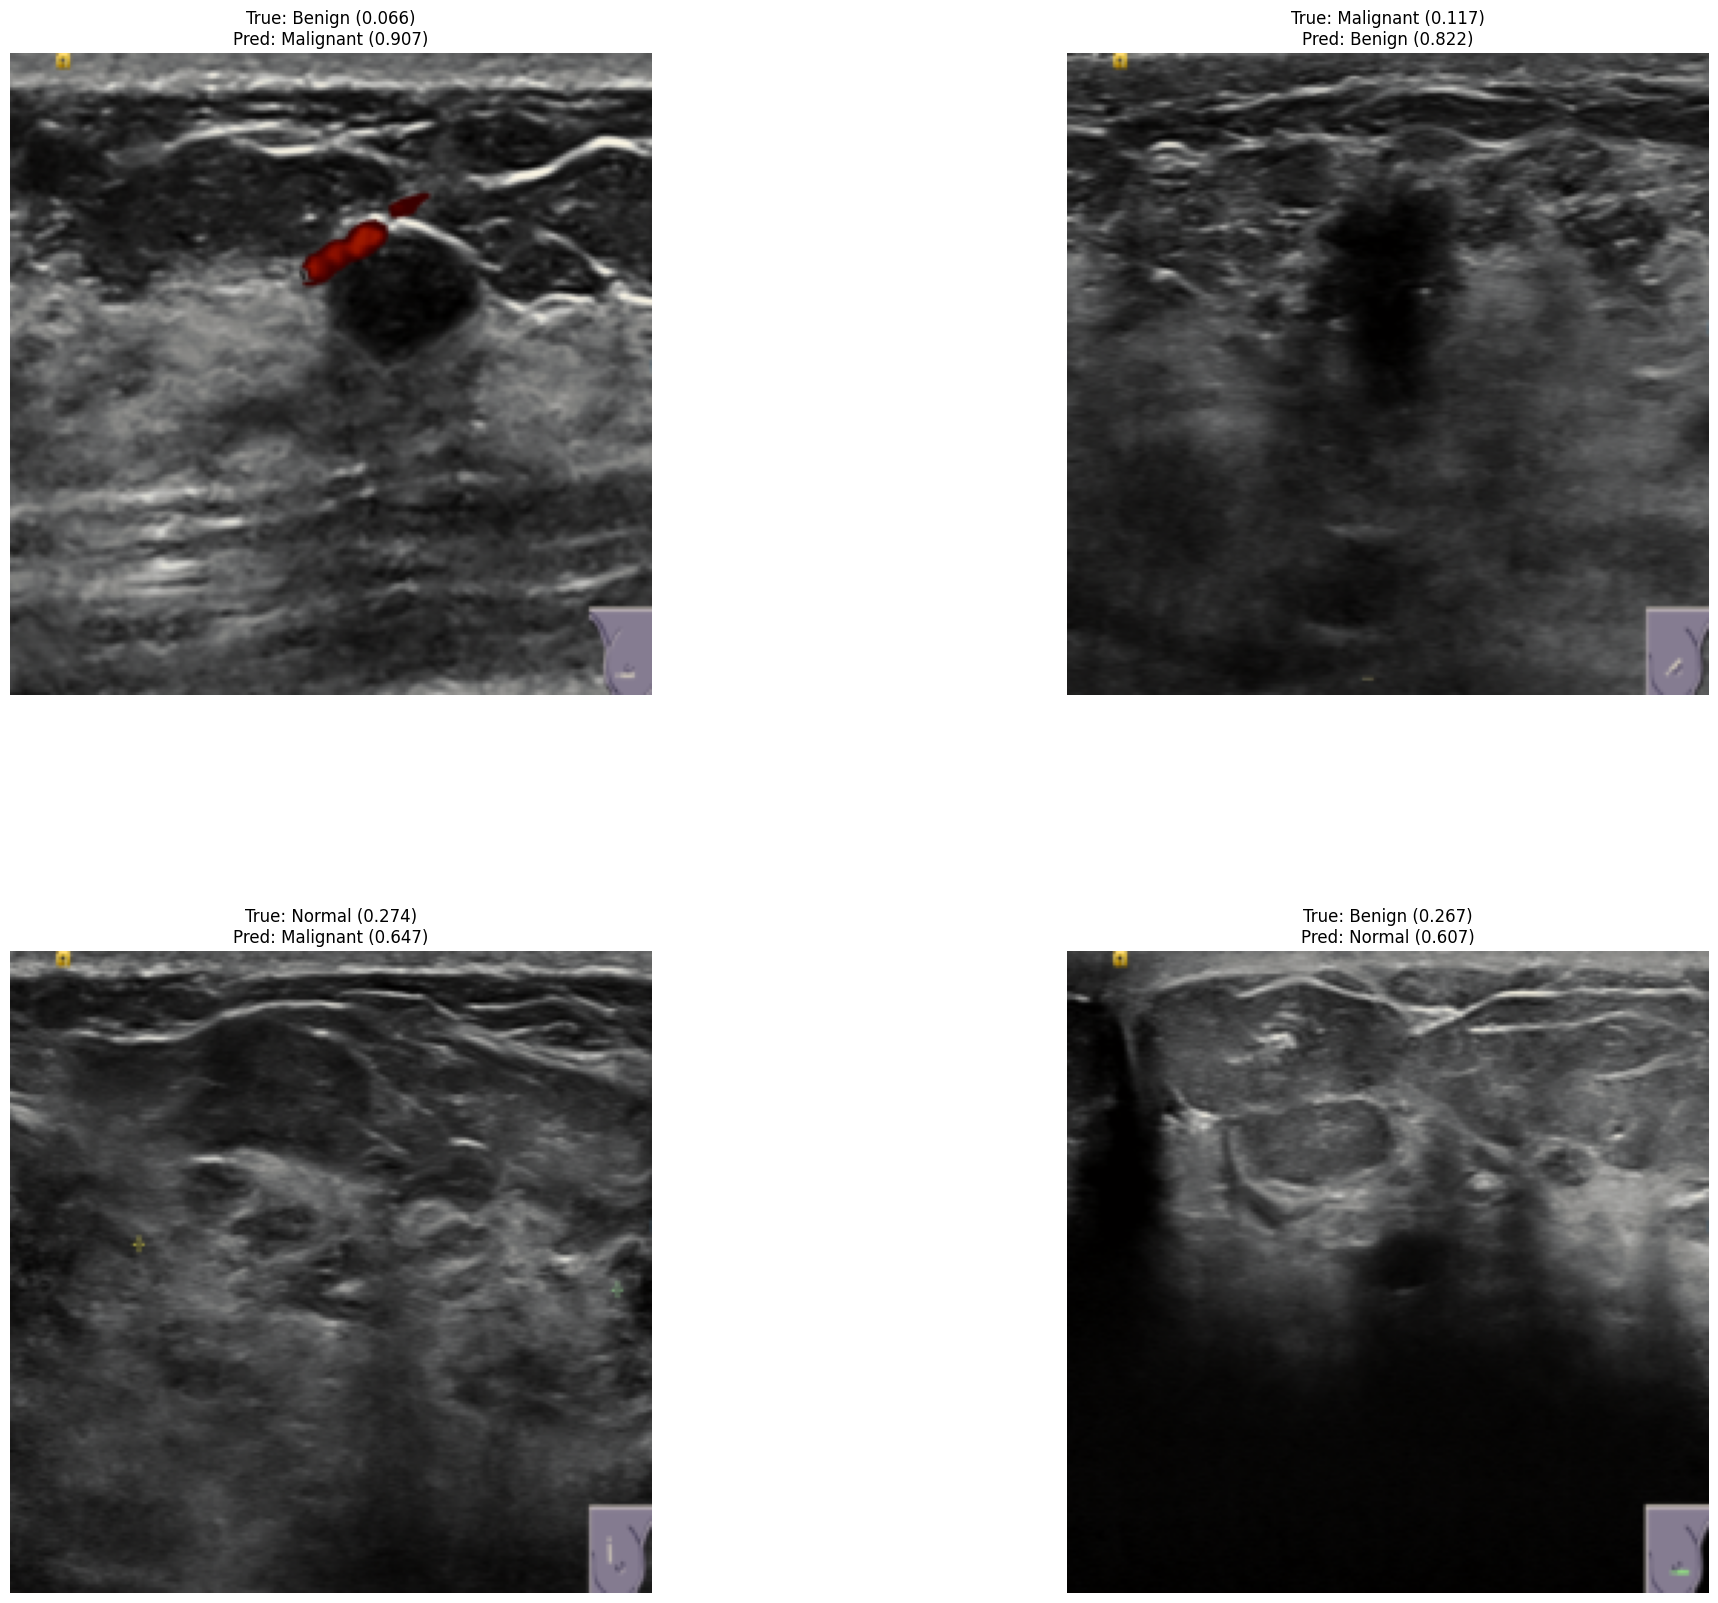

In [37]:
corrects = torch.eq(torch.tensor(all_labels), torch.tensor(all_preds))
num_correct = corrects.sum().item()
total = len(corrects)
print(f"Correct Predictions: {num_correct}/{total} ({100 * num_correct / total:.2f}%)")

incorrect_examples = []
for image, label, prob, correct in zip(all_images, all_labels, all_probs, corrects):
    if not correct:
        incorrect_examples.append((image, label, prob))

incorrect_examples.sort(reverse=True, key=lambda x: torch.max(x[2]).item())
N_IMAGES = 6
plot_most_incorrect(incorrect_examples, class_names, N_IMAGES)